In [41]:
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier,plot_tree,export_text
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [42]:
file_path = "car_evaluation.csv"
data = pd.read_csv(file_path)
print("Original Dataset")
print(data.head())

Original Dataset
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc


In [43]:
data.shape

(1728, 7)

In [44]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   buying    1728 non-null   str  
 1   maint     1728 non-null   str  
 2   doors     1728 non-null   str  
 3   persons   1728 non-null   str  
 4   lug_boot  1728 non-null   str  
 5   safety    1728 non-null   str  
 6   class     1728 non-null   str  
dtypes: str(7)
memory usage: 94.6 KB
None


In [45]:
print(data.describe())

       buying  maint doors persons lug_boot safety  class
count    1728   1728  1728    1728     1728   1728   1728
unique      4      4     4       3        3      3      4
top     vhigh  vhigh     2       2    small    low  unacc
freq      432    432   432     576      576    576   1210


In [46]:
print(data.isnull().values.any())

False


In [47]:
print("\nMissing values:")
print(data.isnull().sum())


Missing values:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64


In [48]:
x=data.drop(columns=['class'])
y=data['class']

In [49]:
encoder = OrdinalEncoder()
x_encoded=pd.DataFrame(encoder.fit_transform(x),columns=x.columns)

print("\nEncoded Labels")
print(x_encoded.head())


Encoded Labels
   buying  maint  doors  persons  lug_boot  safety
0     3.0    3.0    0.0      0.0       2.0     1.0
1     3.0    3.0    0.0      0.0       2.0     2.0
2     3.0    3.0    0.0      0.0       2.0     0.0
3     3.0    3.0    0.0      0.0       1.0     1.0
4     3.0    3.0    0.0      0.0       1.0     2.0


In [50]:
print(x)
print(y)

     buying  maint  doors persons lug_boot safety
0     vhigh  vhigh      2       2    small    low
1     vhigh  vhigh      2       2    small    med
2     vhigh  vhigh      2       2    small   high
3     vhigh  vhigh      2       2      med    low
4     vhigh  vhigh      2       2      med    med
...     ...    ...    ...     ...      ...    ...
1723    low    low  5more    more      med    med
1724    low    low  5more    more      med   high
1725    low    low  5more    more      big    low
1726    low    low  5more    more      big    med
1727    low    low  5more    more      big   high

[1728 rows x 6 columns]
0       unacc
1       unacc
2       unacc
3       unacc
4       unacc
        ...  
1723     good
1724    vgood
1725    unacc
1726     good
1727    vgood
Name: class, Length: 1728, dtype: str


In [51]:
print(data.isnull().values.any())

False


In [52]:
scaler = StandardScaler()
x_Scaled = scaler.fit_transform(x_encoded)
print("\n Scaled features (first 5 rows)")
print(x_Scaled[:5])


 Scaled features (first 5 rows)
[[ 1.34164079  1.34164079 -1.34164079 -1.22474487  1.22474487  0.        ]
 [ 1.34164079  1.34164079 -1.34164079 -1.22474487  1.22474487  1.22474487]
 [ 1.34164079  1.34164079 -1.34164079 -1.22474487  1.22474487 -1.22474487]
 [ 1.34164079  1.34164079 -1.34164079 -1.22474487  0.          0.        ]
 [ 1.34164079  1.34164079 -1.34164079 -1.22474487  0.          1.22474487]]


In [53]:
print(y)

0       unacc
1       unacc
2       unacc
3       unacc
4       unacc
        ...  
1723     good
1724    vgood
1725    unacc
1726     good
1727    vgood
Name: class, Length: 1728, dtype: str


In [54]:
X_train, X_test, y_train, y_test = train_test_split(x_Scaled,y,test_size=0.2, random_state=42, stratify=y)
print("\nTraining samples :",len(X_train))
print("Testing samples :",len(X_test))
print("\nPreprocessing Completed Successfully!")


Training samples : 1382
Testing samples : 346

Preprocessing Completed Successfully!


In [55]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled= scaler.transform(X_test)
print("\n Scaled Features (First 5 rows)")
print(X_train_scaled[:5])


 Scaled Features (First 5 rows)
[[ 0.44471024  0.46853425 -0.42542184 -0.02112909  0.00798628  1.24832681]
 [ 0.44471024 -1.34269466 -0.42542184 -1.23781227  1.23432408  1.24832681]
 [-0.43705383 -1.34269466  1.35349793  1.1955541   1.23432408  1.24832681]
 [ 0.44471024 -0.4370802  -1.31488173 -0.02112909  0.00798628 -1.20745632]
 [ 1.32647432 -0.4370802  -0.42542184 -1.23781227  1.23432408 -1.20745632]]


In [56]:
dt = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42)

In [57]:
dt.fit(X_train_scaled, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [58]:
y_pred=dt.predict(X_test_scaled)

In [59]:
print("\nAccuracy:",accuracy_score(y_test,y_pred))
print("\nConfusion matrix:\n",confusion_matrix(y_test,y_pred))
print("\nclassification rpt:\n",classification_report(y_test,y_pred))


Accuracy: 0.7774566473988439

Confusion matrix:
 [[ 68   0   9   0]
 [ 14   0   0   0]
 [ 41   0 201   0]
 [ 13   0   0   0]]

classification rpt:
               precision    recall  f1-score   support

         acc       0.50      0.88      0.64        77
        good       0.00      0.00      0.00        14
       unacc       0.96      0.83      0.89       242
       vgood       0.00      0.00      0.00        13

    accuracy                           0.78       346
   macro avg       0.36      0.43      0.38       346
weighted avg       0.78      0.78      0.76       346



C:\Users\KH.EN.U4BCA24259\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\KH.EN.U4BCA24259\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\KH.EN.U4BCA24259\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

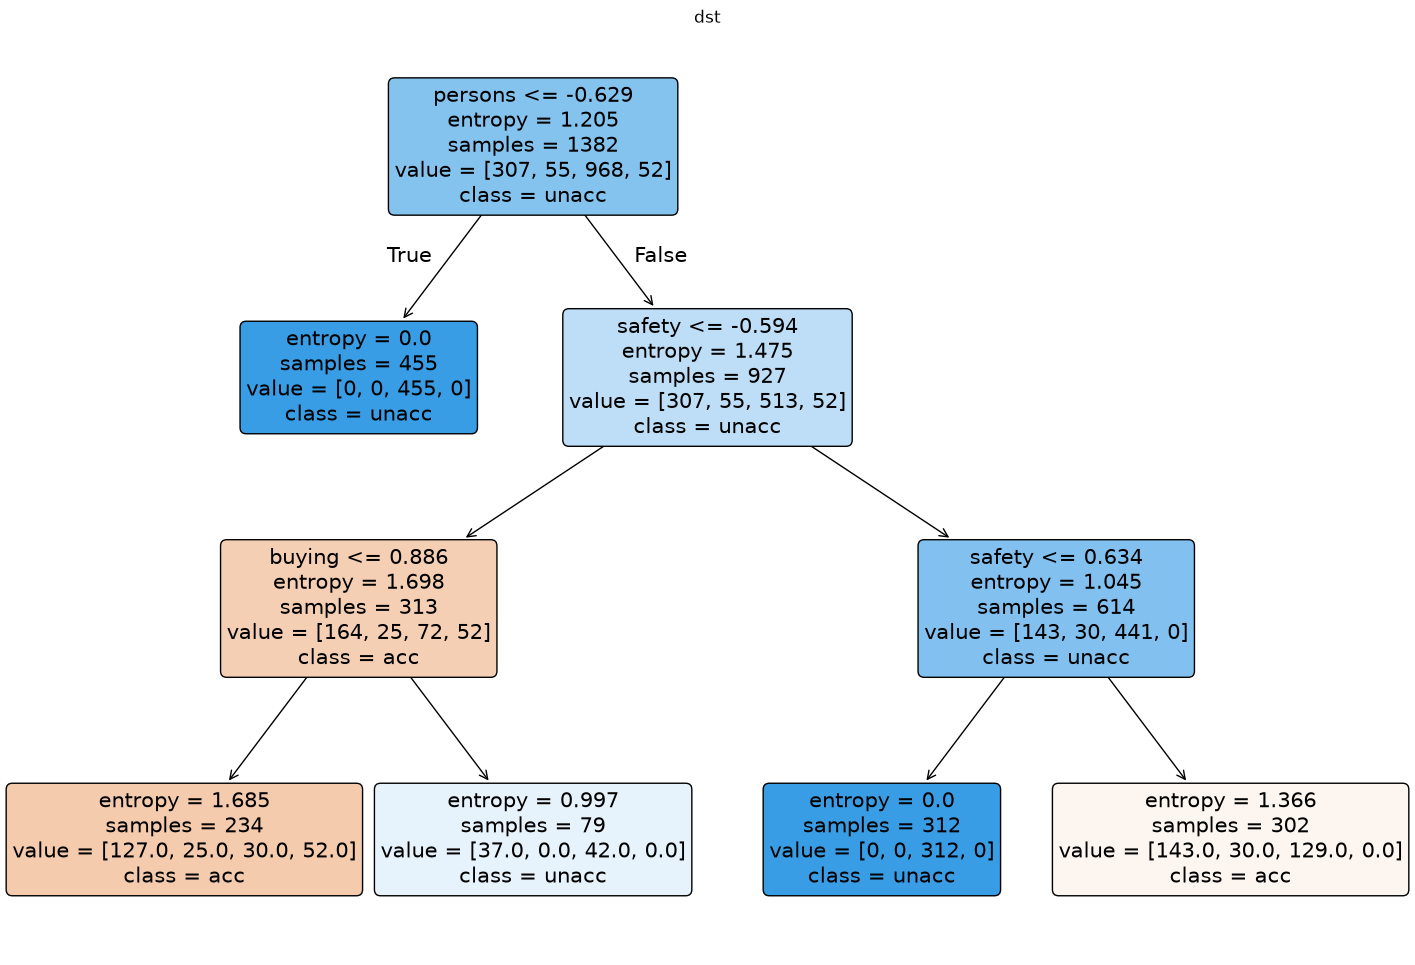

In [61]:
plt.figure(figsize=(18,12))
plot_tree(dt,feature_names=x.columns,class_names=dt.classes_,filled=True,rounded=True)
plt.title("dst")
plt.show()

In [67]:
sample = [['high', 'high', '4', 'more', 'big', 'med']]
sample_encoded = encoder.transform(sample)
sample_scaled = scaler.transform(sample_encoded)
prediction = dt.predict(sample_scaled)
print("\n pred =", prediction)


 pred = ['acc']


C:\Users\KH.EN.U4BCA24259\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but OrdinalEncoder was fitted with feature names
  warnings.warn(
